In [1]:
import pandas as pd

In [6]:
df = pd.read_csv("customer_support_tickets_cleaned.csv")
df.head(20)

,Ticket ID,Product Purchased,Ticket Type,Ticket Status,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,T-001,GoPro Hero,Technical issue,Pending,Critical,Social media,01-06-2023 12:15,NaN,NaN
1,T-002,LG Smart TV,Technical issue,Pending,Critical,Chat,01-06-2023 16:45,NaN,NaN
2,T-003,Dell XPS,Technical issue,Closed,Low,Social media,01-06-2023 11:14,01-06-2023 18:05,3.0
3,T-004,Microsoft Office,Billing inquiry,Closed,Low,Social media,01-06-2023 07:29,01-06-2023 01:57,3.0
4,T-005,Autodesk AutoCAD,Billing inquiry,Closed,Low,Email,01-06-2023 00:12,01-06-2023 19:53,1.0
5,T-006,Microsoft Office,Cancellation request,Open,Low,Social media,NaN,NaN,NaN
6,T-007,Microsoft Surface,Product inquiry,Open,Critical,Social media,NaN,NaN,NaN
7,T-008,Philips Hue Lights,Refund request,Open,Critical,Social media,NaN,NaN,NaN
8,T-009,Fitbit Versa Smartwatch,Technical issue,Pending,Low,Social media,01-06-2023 10:32,NaN,NaN
9,T-010,Dyson Vacuum Cleaner,Refund request,Pending,Critical,Phone,01-06-2023 09:25,NaN,NaN


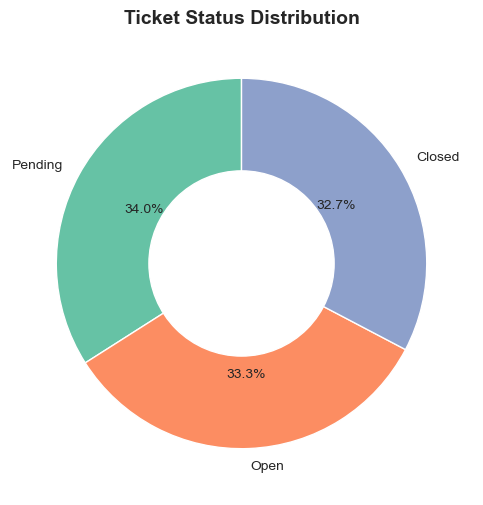

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
status_counts = df["Ticket Status"].value_counts()

# Seaborn style
sns.set_style("whitegrid")

# Colors
colors = sns.color_palette("Set2", len(status_counts))

# Create figure
fig, ax = plt.subplots(figsize=(5, 6))

# Donut chart
wedges, texts, autotexts = ax.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white"}
)

# Create center circle
centre_circle = plt.Circle((0, 0), 0.50, fc="white")
fig.gca().add_artist(centre_circle)

# Title
plt.title("Ticket Status Distribution", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

C:\Users\parth\AppData\Local\Temp\ipykernel_13508\2414353749.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


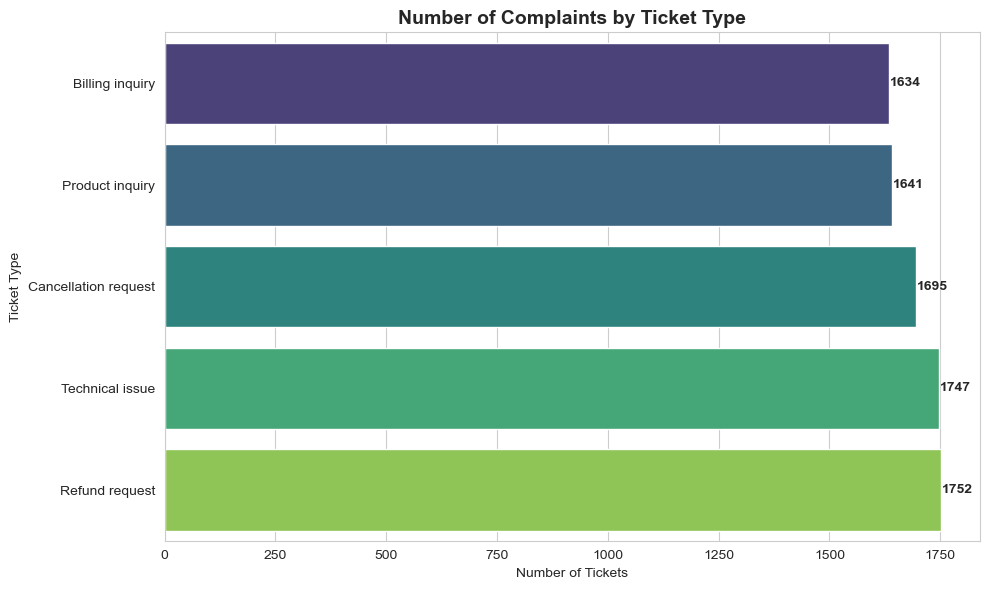

In [5]:
ticket_type_counts = (
    df["Ticket Type"]
    .value_counts()
    .sort_values(ascending=True)
)

# Style
sns.set_style("whitegrid")

# Plot
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=ticket_type_counts.values,
    y=ticket_type_counts.index,
    palette="viridis"
)

# Add values on bars
for i, value in enumerate(ticket_type_counts.values):
    ax.text(
        value + 2,
        i,
        str(value),
        va="center",
        fontweight="bold"
    )

plt.title(
    "Number of Complaints by Ticket Type",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Number of Tickets")
plt.ylabel("Ticket Type")

plt.tight_layout()
plt.show()

In [4]:
df["Ticket Type"].value_counts()

Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

In [7]:
import pandas as pd

df["First Response Time"] = pd.to_datetime(
    df["First Response Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

df["Time to Resolution"] = pd.to_datetime(
    df["Time to Resolution"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

invalid_records = df[
    df["Time to Resolution"] < df["First Response Time"]
]

print(f"Invalid records: {len(invalid_records)}")
display(invalid_records[[
    "Ticket ID",
    "First Response Time",
    "Time to Resolution"
]])


Invalid records: 1365


,Ticket ID,First Response Time,Time to Resolution
3,T-004,2023-06-01 07:29:00,2023-06-01 01:57:00
10,T-011,2023-06-01 17:46:00,2023-05-31 23:51:00
11,T-012,2023-06-01 12:05:00,2023-06-01 09:27:00
14,T-015,2023-06-01 06:22:00,2023-05-31 23:08:00
16,T-017,2023-06-01 19:46:00,2023-06-01 15:58:00
...,...,...,...
8452,T-8453,2023-06-01 14:14:00,2023-06-01 05:47:00
8453,T-8454,2023-06-01 12:56:00,2023-06-01 04:45:00
8455,T-8456,2023-06-01 14:15:00,2023-06-01 06:58:00
8466,T-8467,2023-06-01 09:44:00,2023-06-01 04:31:00


In [10]:
import pandas as pd

# Convert datetime columns
df["First Response Time"] = pd.to_datetime(
    df["First Response Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

df["Time to Resolution"] = pd.to_datetime(
    df["Time to Resolution"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Invalid records:
# Resolution before First Response
invalid_df = df[
    (df["Time to Resolution"].notna()) &
    (df["First Response Time"].notna()) &
    (df["Time to Resolution"] < df["First Response Time"])
]

print(f"Total Invalid Records: {len(invalid_df)}")

# Show all invalid rows
display(
    invalid_df[
        [
            "Ticket ID",
            "Ticket Type",
            "Ticket Status",
            "First Response Time",
            "Time to Resolution"
        ]
    ]
)

Total Invalid Records: 1365


,Ticket ID,Ticket Type,Ticket Status,First Response Time,Time to Resolution
3,T-004,Billing inquiry,Closed,2023-06-01 07:29:00,2023-06-01 01:57:00
10,T-011,Cancellation request,Closed,2023-06-01 17:46:00,2023-05-31 23:51:00
11,T-012,Product inquiry,Closed,2023-06-01 12:05:00,2023-06-01 09:27:00
14,T-015,Billing inquiry,Closed,2023-06-01 06:22:00,2023-05-31 23:08:00
16,T-017,Product inquiry,Closed,2023-06-01 19:46:00,2023-06-01 15:58:00
...,...,...,...,...,...
8452,T-8453,Refund request,Closed,2023-06-01 14:14:00,2023-06-01 05:47:00
8453,T-8454,Billing inquiry,Closed,2023-06-01 12:56:00,2023-06-01 04:45:00
8455,T-8456,Billing inquiry,Closed,2023-06-01 14:15:00,2023-06-01 06:58:00
8466,T-8467,Technical issue,Closed,2023-06-01 09:44:00,2023-06-01 04:31:00


In [12]:
import pandas as pd

# Datetime conversion
df["First Response Time"] = pd.to_datetime(df["First Response Time"])
df["Time to Resolution"] = pd.to_datetime(df["Time to Resolution"])

# Invalid records
invalid_mask = (
    df["Time to Resolution"].notna() &
    df["First Response Time"].notna() &
    (df["Time to Resolution"] < df["First Response Time"])
)

# 1 June wale invalid records -> +1 day
june_1_mask = (
    invalid_mask &
    (df["Time to Resolution"].dt.date == pd.Timestamp("2023-06-01").date())
)

df.loc[june_1_mask, "Time to Resolution"] += pd.Timedelta(days=1)

# 31 May wale invalid records -> +2 days
may_31_mask = (
    invalid_mask &
    (df["Time to Resolution"].dt.date == pd.Timestamp("2023-05-31").date())
)

df.loc[may_31_mask, "Time to Resolution"] += pd.Timedelta(days=2)

# Check again
remaining_invalid = (
    df["Time to Resolution"].notna() &
    df["First Response Time"].notna() &
    (df["Time to Resolution"] < df["First Response Time"])
)

print("Remaining Invalid Records:", remaining_invalid.sum())

Remaining Invalid Records: 1


In [13]:
import pandas as pd

# Convert datetime columns
df["First Response Time"] = pd.to_datetime(
    df["First Response Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

df["Time to Resolution"] = pd.to_datetime(
    df["Time to Resolution"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Invalid records:
# Resolution before First Response
invalid_df = df[
    (df["Time to Resolution"].notna()) &
    (df["First Response Time"].notna()) &
    (df["Time to Resolution"] < df["First Response Time"])
]

print(f"Total Invalid Records: {len(invalid_df)}")

# Show all invalid rows
display(
    invalid_df[
        [
            "Ticket ID",
            "Ticket Type",
            "Ticket Status",
            "First Response Time",
            "Time to Resolution"
        ]
    ]
)

Total Invalid Records: 1


,Ticket ID,Ticket Type,Ticket Status,First Response Time,Time to Resolution
7302,T-7303,Billing inquiry,Closed,2023-06-02 00:30:00,2023-06-02


In [15]:
# Pehle backup bana lo
df.to_csv(
    "customer_support_tickets_backup.csv",
    index=False
)

# Fir cleaned data overwrite karo
df.to_csv(
    "customer_support_tickets_cleaned.csv",
    index=False
)

PermissionError: [Errno 13] Permission denied: 'customer_support_tickets_cleaned.csv'